# Dataset Exploration — Breast Cancer Wisconsin (Original)

**Dataset:** UCI Breast Cancer Wisconsin (Original)  
**Source:** Wolberg, W. (1990). *Breast Cancer Wisconsin (Original)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5HP4Z

## Purpose

This notebook explores the structure and quality of the Breast Cancer Wisconsin (Original) dataset as part of a supervised machine-learning classification project. The goal is to understand what the dataset contains before any preprocessing or modelling begins.

**Scope:** This notebook covers only **Dataset Exploration**. It does not perform preprocessing (e.g., imputation, duplicate removal, feature scaling) or model training, which are handled in later project tasks by other team members.

### What this notebook covers

1. Loading the dataset and verifying its structure.
2. Identifying the identifier, predictive features, and target variable.
3. Summarising feature meanings from the dataset documentation.
4. Computing descriptive statistics for the predictive features.
5. Investigating missing values, duplicate records, and class distribution.

---
## 1. Imports and Dataset Loading

We load the dataset from the `.data` file using Pandas. Key points about the loading process:

- **`header=None`** — The file contains only data rows; there is no header line with column names.
- **`names=column_names`** — We supply the 11 column names in the order defined by the dataset documentation (`breast-cancer-wisconsin.names`).
- **`na_values="?"`** — The documentation states that 16 instances contain a missing attribute value represented by `"?"`. Passing this to `na_values` causes Pandas to interpret those entries as `NaN` during loading, so we do not need to replace them manually afterward.

In [1]:
import pandas as pd
import numpy as np

In [2]:
import os

# Column names in the order specified by the dataset documentation
column_names = [
    "sample_code_number",
    "clump_thickness",
    "uniformity_of_cell_size",
    "uniformity_of_cell_shape",
    "marginal_adhesion",
    "single_epithelial_cell_size",
    "bare_nuclei",
    "bland_chromatin",
    "normal_nucleoli",
    "mitoses",
    "class",
]

# The nine predictive features (columns 2–10 in the documentation)
feature_names = column_names[1:10]

# Locate data file whether running from root or data directory
data_path = "breast-cancer-wisconsin.data"
if not os.path.exists(data_path):
    data_path = os.path.join("data", "breast-cancer-wisconsin.data")

df = pd.read_csv(
    data_path,
    header=None,
    names=column_names,
    na_values="?",
)

print(f"Dataset loaded successfully from: {data_path}")
print(f"Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")

Dataset loaded successfully from: data\breast-cancer-wisconsin.data
Dimensions: 699 rows × 11 columns


---
## 2. Dataset Structure

### 2.1 First and last rows

Displaying the first and last five rows gives a quick visual check that the data loaded correctly and that column names, data types, and values look reasonable.

In [3]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,sample_code_number,clump_thickness,uniformity_of_cell_size,uniformity_of_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class
0,1000025,5,1,1,1,2,1.0,3,1,1,2
1,1002945,5,4,4,5,7,10.0,3,2,1,2
2,1015425,3,1,1,1,2,2.0,3,1,1,2
3,1016277,6,8,8,1,3,4.0,3,7,1,2
4,1017023,4,1,1,3,2,1.0,3,1,1,2



Last 5 rows:


,sample_code_number,clump_thickness,uniformity_of_cell_size,uniformity_of_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class
694,776715,3,1,1,1,3,2.0,1,1,1,2
695,841769,2,1,1,1,2,1.0,1,1,1,2
696,888820,5,10,10,3,7,3.0,8,10,2,4
697,897471,4,8,6,4,3,4.0,10,6,1,4
698,897471,4,8,8,5,4,5.0,10,4,1,4


### 2.2 Column names and data types

The `info()` method shows each column's name, non-null count, and data type in a single compact summary. This helps us verify that the column names match the documentation and spot any unexpected types.

**Expected observation:** All columns should be numeric. `bare_nuclei` should appear as `float64` rather than `int64` because its 16 missing values are stored as `NaN`, and Pandas uses floating-point to accommodate `NaN` in an otherwise integer column.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   sample_code_number           699 non-null    int64  
 1   clump_thickness              699 non-null    int64  
 2   uniformity_of_cell_size      699 non-null    int64  
 3   uniformity_of_cell_shape     699 non-null    int64  
 4   marginal_adhesion            699 non-null    int64  
 5   single_epithelial_cell_size  699 non-null    int64  
 6   bare_nuclei                  683 non-null    float64
 7   bland_chromatin              699 non-null    int64  
 8   normal_nucleoli              699 non-null    int64  
 9   mitoses                      699 non-null    int64  
 10  class                        699 non-null    int64  
dtypes: float64(1), int64(10)
memory usage: 60.2 KB


### 2.3 Identifier, predictive features, and target variable

According to the dataset documentation:

| Role | Column(s) | Description |
|------|-----------|-------------|
| **Identifier** | `sample_code_number` | Patient ID number. Not a predictive feature. |
| **Predictive features** | `clump_thickness` through `mitoses` (9 columns) | Cytological characteristics scored from 1 to 10. |
| **Target** | `class` | Diagnosis label: **2 = benign**, **4 = malignant**. |

The nine predictive features represent attributes of cell nuclei observed in fine-needle aspirate (FNA) images. Each is an integer score on a 1–10 scale as defined in the documentation. The documentation lists the attribute names and their scoring domain (1–10) but does not provide detailed clinical definitions of what each score level means.

In [5]:
print("Identifier column:")
print(f"  {column_names[0]}")

print(f"\nPredictive features ({len(feature_names)} columns):")
for name in feature_names:
    print(f"  {name}")

print(f"\nTarget variable:")
print(f"  {column_names[-1]}  →  2 = benign, 4 = malignant")

Identifier column:
  sample_code_number

Predictive features (9 columns):
  clump_thickness
  uniformity_of_cell_size
  uniformity_of_cell_shape
  marginal_adhesion
  single_epithelial_cell_size
  bare_nuclei
  bland_chromatin
  normal_nucleoli
  mitoses

Target variable:
  class  →  2 = benign, 4 = malignant


### 2.4 Feature meanings

The following table summarises each predictive feature based on the dataset documentation (`breast-cancer-wisconsin.names`). All features are integer scores on a 1–10 scale derived from microscopic examination of breast tissue samples.

| # | Feature | Domain | Description |
|---|---------|--------|-------------|
| 1 | `clump_thickness` | 1–10 | Thickness of cell clumps. |
| 2 | `uniformity_of_cell_size` | 1–10 | Uniformity of cell sizes. |
| 3 | `uniformity_of_cell_shape` | 1–10 | Uniformity of cell shapes. |
| 4 | `marginal_adhesion` | 1–10 | Marginal adhesion of cells. |
| 5 | `single_epithelial_cell_size` | 1–10 | Size of single epithelial cells. |
| 6 | `bare_nuclei` | 1–10 | Bare nuclei presence (contains 16 missing values). |
| 7 | `bland_chromatin` | 1–10 | Bland chromatin texture. |
| 8 | `normal_nucleoli` | 1–10 | Normal nucleoli characteristics. |
| 9 | `mitoses` | 1–10 | Mitotic activity. |

**Note:** The documentation describes these attributes at a high level. It does not provide detailed clinical interpretations for individual score values, so we avoid making specific medical claims about what a particular score means beyond what is documented.

---
## 3. Descriptive Statistics

We compute descriptive statistics for the **nine predictive features only**. The identifier (`sample_code_number`) is excluded because it is an arbitrary ID with no analytical meaning. The target (`class`) is excluded because its values (2 and 4) are categorical codes, not continuous measurements — computing a mean or standard deviation of class codes would not be clinically meaningful.

The `describe()` output includes:

| Statistic | Meaning |
|-----------|---------|
| **count** | Number of non-missing values. A count lower than 699 indicates missing data in that column. |
| **mean** | Arithmetic average of the values. |
| **std** | Standard deviation — measures how spread out the values are around the mean. |
| **min** | Smallest observed value. |
| **25%** | First quartile (Q1) — 25% of values fall below this point. |
| **50%** | Median (Q2) — the middle value when sorted. |
| **75%** | Third quartile (Q3) — 75% of values fall below this point. |
| **max** | Largest observed value. |

In [6]:
# Descriptive statistics for the 9 predictive features only
df[feature_names].describe().round(2)

,clump_thickness,uniformity_of_cell_size,uniformity_of_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses
count,699.00,699.00,699.00,699.00,699.00,683.00,699.00,699.00,699.00
mean,4.42,3.13,3.21,2.81,3.22,3.54,3.44,2.87,1.59
std,2.82,3.05,2.97,2.86,2.21,3.64,2.44,3.05,1.72
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2.00,1.00,1.00,1.00,2.00,1.00,2.00,1.00,1.00
50%,4.00,1.00,1.00,1.00,2.00,1.00,3.00,1.00,1.00
75%,6.00,5.00,5.00,4.00,4.00,6.00,5.00,4.00,1.00
max,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00


### Observations

- **`bare_nuclei`** has a count of 683 instead of 699, confirming 16 missing values.
- All features have a minimum of 1 and a maximum of 10, consistent with the documented 1–10 scoring range.
- Several features (`uniformity_of_cell_size`, `uniformity_of_cell_shape`, `marginal_adhesion`, `single_epithelial_cell_size`, `bare_nuclei`, `normal_nucleoli`, `mitoses`) have a median (50th percentile) of 1, suggesting that the majority of samples have low scores for these features. This is consistent with the dataset being majority benign (as we will confirm in the class distribution below).
- Features with relatively higher means (e.g., `clump_thickness` and `bland_chromatin`) exhibit more spread across the scoring range.

---
## 4. Data Quality Exploration

### 4.1 Missing values

We count missing values (`NaN`) per column. Recall that `"?"` entries in the original file were converted to `NaN` during loading via the `na_values="?"` parameter.

In [7]:
# Count missing values per column
missing_count = df.isna().sum()
missing_percentage = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percentage,
})

display(missing_summary)
print(f"Total missing values: {missing_count.sum()}")

,Missing Count,Missing %
sample_code_number,0,0.00
clump_thickness,0,0.00
uniformity_of_cell_size,0,0.00
uniformity_of_cell_shape,0,0.00
marginal_adhesion,0,0.00
single_epithelial_cell_size,0,0.00
bare_nuclei,16,2.29
bland_chromatin,0,0.00
normal_nucleoli,0,0.00
mitoses,0,0.00


Total missing values: 16


**Interpretation:** Only `bare_nuclei` contains missing values — 16 out of 699 records (approximately 2.29%). The dataset documentation confirms this: *"There are 16 instances in Groups 1 to 6 that contain a single missing (i.e., unavailable) attribute value, now denoted by '?'."*

The `bare_nuclei` column is stored as `float64` rather than `int64` because Pandas uses floating-point to represent integer columns that contain `NaN`. This is a technical detail of how Pandas handles missing data, not a data quality issue.

**Note:** Handling these missing values (e.g., imputation or removal) is a preprocessing decision and is not performed in this exploration notebook.

### 4.2 Duplicate analysis

"Duplicate" can mean different things depending on which columns we compare. We examine three distinct definitions:

1. **Exact duplicate rows** — rows where *all 11 columns* are identical.
2. **Repeated identifiers** — rows sharing the same `sample_code_number` (patient ID), which may represent repeat visits or data-entry reuse.
3. **Repeated predictive-feature profiles** — rows where the 9 predictive feature values are identical, regardless of the identifier or target.

These categories **overlap** and use different definitions, so their counts should never be added together.

In each case, `duplicated(keep='first')` counts only the *extra* occurrences (the first appearance is not counted as a duplicate).

In [8]:
# 1. Exact duplicate rows (all 11 columns identical)
exact_dupes = df.duplicated(keep='first').sum()
print(f"Exact duplicate rows (extra occurrences): {exact_dupes}")

# 2. Repeated identifiers (same sample_code_number)
repeated_ids = df['sample_code_number'].duplicated(keep='first').sum()
print(f"Repeated identifiers (extra occurrences):  {repeated_ids}")

# 3. Repeated predictive-feature profiles (same 9 feature values)
repeated_profiles = df.duplicated(subset=feature_names, keep='first').sum()
print(f"Repeated feature profiles (extra occurrences): {repeated_profiles}")

Exact duplicate rows (extra occurrences): 8
Repeated identifiers (extra occurrences):  54
Repeated feature profiles (extra occurrences): 236


**Interpretation:**

- **8 exact duplicate rows:** These are rows where all 11 values (including the identifier and target) are completely identical to an earlier row. These may represent data-entry errors or re-submissions.
- **54 repeated identifiers:** The same `sample_code_number` appears more than once. The dataset documentation notes that samples arrived in chronological batches, so the same patient could have multiple records collected at different times. A repeated identifier does not automatically indicate a data error.
- **236 repeated feature profiles:** When looking at only the 9 predictive features, 236 rows match an earlier row. This is a broader count because different patients can have identical cytological scores. Rows with the same feature values may have different identifiers or different target labels.

**Note:** Whether to remove any of these duplicates is a preprocessing decision and is not performed in this exploration notebook.

### 4.3 Target class distribution

The target variable `class` has two values: **2 (benign)** and **4 (malignant)**. We report the count and percentage of each class.

In [9]:
class_counts = df["class"].value_counts().sort_index()
class_percentages = (class_counts / len(df) * 100).round(1)

class_summary = pd.DataFrame({
    "Label": {2: "Benign", 4: "Malignant"},
    "Count": class_counts,
    "Percentage": class_percentages.astype(str) + "%",
})

display(class_summary)
print(f"Total samples: {len(df)}")

,Label,Count,Percentage
2,Benign,458,65.5%
4,Malignant,241,34.5%


Total samples: 699


**Interpretation:** The dataset contains 458 benign samples (65.5%) and 241 malignant samples (34.5%). This confirms the class distribution stated in the documentation.

The dataset is moderately imbalanced toward the benign class, with a roughly 2:1 ratio. This imbalance is worth noting for later modelling stages, as it can affect classifier performance — particularly for metrics like precision and recall on the malignant (minority) class. However, addressing class imbalance is outside the scope of this exploration task.

---
## 5. Exploration Summary

### Key findings

| Aspect | Finding |
|--------|---------|
| **Dimensions** | 699 rows × 11 columns |
| **Features** | 9 predictive features (integer scores, 1–10 scale) |
| **Identifier** | `sample_code_number` (patient ID, not a predictive feature) |
| **Target** | `class` — 2 (benign) or 4 (malignant) |
| **Missing values** | 16 in `bare_nuclei` (2.29% of rows) |
| **Exact duplicate rows** | 8 extra occurrences |
| **Repeated identifiers** | 54 extra occurrences |
| **Repeated feature profiles** | 236 extra occurrences |
| **Class distribution** | 458 benign (65.5%) / 241 malignant (34.5%) |

### Observations and limitations

- The dataset is relatively small (699 records) and was collected in chronological batches — the original row order is not random.
- Missing values are confined to a single column (`bare_nuclei`) and affect a small proportion of records.
- The three types of duplicates examined use different definitions and overlap. Identical feature profiles can belong to different patients and may even have different diagnoses, so they are not necessarily errors.
- The class labels (2 and 4) are categorical codes, not ordinal or continuous values.
- Moderate class imbalance exists and should be considered in model evaluation.


# Data Preprocessing

## 1. Objective

The objective of this task is to prepare the Breast Cancer Wisconsin (Original) dataset for supervised machine learning classification.

The preprocessing process includes:
- Preserving the original dataset.
- Identifying and removing exact duplicate records.
- Separating input features from the target variable.
- Excluding irrelevant features, such as the sample ID.
- Splitting the dataset into training and testing sets.
- Handling missing values.
- Applying feature standardization where necessary.
- Preventing data leakage by fitting preprocessing steps using the training data only.

The target variable represents two classes:
- `2`: Benign
- `4`: Malignant

For model evaluation, malignant cases will be treated as the positive class.


## 2. Create a Working Copy

The dataset was loaded and explored in Task 1. Therefore, it does not need to be loaded again as long as the original DataFrame `df` is still available in the current notebook session.

A separate working copy will be created to preserve the original dataset and allow preprocessing without modifying the original data.

In [10]:
# Preserve the original dataset and create a working copy
df_original = df.copy()
df_clean = df.copy()
feature_columns = feature_names

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (699, 11)
Working dataset shape: (699, 11)



## 3. Duplicate Records

Exact duplicate records are rows in which all column values are identical.

Duplicate records may cause some observations to be counted more than once. Therefore, exact duplicates will be identified and removed from the working dataset.

Repeated sample IDs or repeated feature values are not automatically considered duplicates, because they may represent different records.

In [11]:
# Count exact duplicate records before removal
duplicates_before = df_clean.duplicated().sum()
print("Exact duplicate records before removal:", duplicates_before)

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Check the dataset after removal
duplicates_after = df_clean.duplicated().sum()
print("Exact duplicate records after removal:", duplicates_after)
print("Dataset shape after removing duplicates:", df_clean.shape)

Exact duplicate records before removal: 8
Exact duplicate records after removal: 0
Dataset shape after removing duplicates: (691, 11)


### Repeated Sample ID Investigation

Exact duplicate records were removed in the previous step. However, repeated sample IDs are a separate data quality issue because records sharing the same `sample_code_number` may have different feature values or target classes.

A further investigation identified:

- 39 repeated sample IDs.
- 85 records belonging to these repeated IDs.
- 4 sample IDs associated with multiple target classes.
- 39 repeated sample IDs with different feature profiles.

These records were not automatically removed because a repeated sample ID does not necessarily indicate an exact duplicate.

To prevent records sharing the same sample ID from appearing in both training and testing sets, a group-aware split was used. This resulted in zero shared sample IDs between the two subsets.

In [12]:

# Investigate repeated sample IDs
id_counts = df_clean.groupby("sample_code_number").size()
repeated_ids = id_counts[id_counts > 1]

# Count distinct target classes for each sample ID
class_counts = df_clean.groupby("sample_code_number")["class"].nunique()
ids_with_multiple_classes = class_counts[class_counts > 1]

# Count distinct feature profiles for each sample ID
feature_profile_counts = df_clean.groupby("sample_code_number")[
    feature_columns
].apply(lambda group: group.drop_duplicates().shape[0])

ids_with_different_features = feature_profile_counts[
    (id_counts > 1) & (feature_profile_counts > 1)
]

print("Repeated sample IDs:", len(repeated_ids))
print("Records belonging to repeated IDs:", int(repeated_ids.sum()))
print("IDs with multiple target classes:", len(ids_with_multiple_classes))
print("Repeated IDs with different feature profiles:",
      len(ids_with_different_features))

Repeated sample IDs: 39
Records belonging to repeated IDs: 85
IDs with multiple target classes: 4
Repeated IDs with different feature profiles: 39



## 4. Separate Features and Target

The dataset contains nine predictive features and one target variable.

The `sample_code_number` column is an identifier rather than a predictive feature, so it will be excluded from the model inputs.

The target variable is `class`, where:
- `2` represents benign cases.
- `4` represents malignant cases.

The target will be encoded as `0` for benign and `1` for malignant. This encoding allows malignant cases to be treated as the positive class during evaluation.

In [13]:
# Separate the nine predictive features from the target
feature_columns = [
    "clump_thickness",
    "uniformity_of_cell_size",
    "uniformity_of_cell_shape",
    "marginal_adhesion",
    "single_epithelial_cell_size",
    "bare_nuclei",
    "bland_chromatin",
    "normal_nucleoli",
    "mitoses"
]

X = df_clean[feature_columns].copy()

# Encode the target: benign = 0, malignant = 1
y = df_clean["class"].map({2: 0, 4: 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index().rename(index={0: "Benign", 1: "Malignant"}))

Features shape: (691, 9)
Target shape: (691,)

Target distribution:
class
Benign       453
Malignant    238
Name: count, dtype: int64



## 5. Group-Aware Train-Test Split

A group-aware split is used to prevent records sharing the same sample ID from appearing in both the training and testing sets.

StratifiedGroupKFold is used to maintain an approximately balanced class distribution while keeping each sample ID within a single subset.

The selected fold provides an approximately 80:20 training-to-testing split.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

groups = df_clean["sample_code_number"]

# StratifiedGroupKFold ensures no patient sample ID appears in both train and test splits
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).rename("Proportion").round(4))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).rename("Proportion").round(4))

# Check for sample IDs shared between training and testing
train_ids = set(groups.iloc[train_idx])
test_ids = set(groups.iloc[test_idx])

shared_ids = train_ids.intersection(test_ids)

print("\nNumber of shared sample IDs:", len(shared_ids))
print("Shared sample IDs:", sorted(shared_ids) if shared_ids else "None")

Training features shape: (552, 9)
Testing features shape: (139, 9)
Training target shape: (552,)
Testing target shape: (139,)

Training class distribution:
class
0    0.6558
1    0.3442
Name: Proportion, dtype: float64

Testing class distribution:
class
0    0.6547
1    0.3453
Name: Proportion, dtype: float64

Number of shared sample IDs: 0
Shared sample IDs: None



## 6. Handle Missing Values

During Task 1, missing values were identified in the `bare_nuclei` feature.

Missing values will be handled using median imputation. The median will be calculated from the training data only and then applied to both the training and testing sets.

This approach prevents information from the test set from influencing the preprocessing process.

In [15]:
from sklearn.impute import SimpleImputer

# Fit the imputer on the training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Missing values in training data after imputation:",
      int(__import__("numpy").isnan(X_train_imputed).sum()))

print("Missing values in testing data after imputation:",
      int(__import__("numpy").isnan(X_test_imputed).sum()))

Missing values in training data after imputation: 0
Missing values in testing data after imputation: 0



## 7. Feature Standardization

Feature standardization transforms numerical features to have approximately zero mean and unit standard deviation.

This step is useful for distance-based and optimization-based models, such as KNN, SVM, and ANN, because features with larger scales may otherwise have an excessive influence on the learning process.

The scaler will be fitted using the training data only and then applied to the testing data to prevent data leakage.

Tree-based models, such as Decision Tree and Random Forest, generally do not require feature standardization.

In [16]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on the training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (552, 9)
Scaled testing data shape: (139, 9)



## 8. Final Preprocessing Checks

The final step is to verify that:
- The training and testing sets have the expected dimensions.
- No missing values remain after imputation.
- The target contains only the encoded classes `0` and `1`.
- The training and testing sets are separate.
- The preprocessing steps were fitted using training data only.

In [17]:
import numpy as np

print("Final preprocessing summary")
print("-" * 40)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("Missing values in training set:",
      int(np.isnan(X_train_imputed).sum()))

print("Missing values in testing set:",
      int(np.isnan(X_test_imputed).sum()))

print("Target classes:", sorted(y.unique()))

print("Training and testing indices overlap:",
      bool(set(X_train.index).intersection(set(X_test.index))))

Final preprocessing summary
----------------------------------------
Training set: (552, 9)
Testing set: (139, 9)
Missing values in training set: 0
Missing values in testing set: 0
Target classes: [np.int64(0), np.int64(1)]
Training and testing indices overlap: False


## Preprocessing Summary

The Breast Cancer Wisconsin (Original) dataset was prepared for supervised machine learning classification.

The preprocessing steps included:

- Preserving the original dataset and creating a working copy.
- Removing 8 exact duplicate records, resulting in 691 records.
- Separating the 9 predictive features from the target variable.
- Mapping the original target labels (2 and 4) to binary labels (0 and 1), representing benign and malignant cases, respectively.
- Investigating repeated sample IDs and documenting records associated with multiple target classes.
- Applying a group-aware train-test split to prevent sample IDs from appearing in both subsets.
- Imputing missing feature values using the median calculated from the training data.
- Applying standardization using statistics learned from the training data only.
- Verifying the final dataset dimensions, target labels, missing values, and numerical validity.

The resulting training set contains 552 records, and the testing set contains 139 records, each with 9 predictive features.

The processed data is ready for the next stage of the machine learning workflow, subject to documenting and reviewing the identified sample ID inconsistencies.

In [18]:

import pandas as pd

# Combine the processed training and testing data
X_train_final = pd.DataFrame(
    X_train_scaled,
    columns=feature_columns,
    index=X_train.index
)

X_test_final = pd.DataFrame(
    X_test_scaled,
    columns=feature_columns,
    index=X_test.index
)

X_final = pd.concat([X_train_final, X_test_final]).sort_index()

# Combine the target values in the same original row order
y_final = pd.concat([y_train, y_test]).sort_index()

# Create the final processed dataset
final_dataset = X_final.copy()
final_dataset["class"] = y_final

# Export to CSV
final_dataset.to_csv("final_preprocessed_dataset.csv", index=False)

print("Final dataset shape:", final_dataset.shape)
print("Missing values:", int(final_dataset.isna().sum().sum()))
print("File saved as: final_preprocessed_dataset.csv")

Final dataset shape: (691, 10)
Missing values: 0
File saved as: final_preprocessed_dataset.csv


---
# Exploratory Data Analysis (EDA)

## 1. Overview and Objectives

Exploratory Data Analysis (EDA) is an essential phase in the machine learning workflow. Before training classification models, we conduct a comprehensive visual and statistical investigation of the Breast Cancer Wisconsin (Original) dataset to uncover underlying patterns, evaluate feature distributions, detect anomalies and outliers, explore feature interrelationships (multicollinearity), and examine the impact of data preprocessing transformations.

### Required Tasks Addressed in this Section:
1. **Missing Value Visualization:** Quantify and visualize missing values per feature using counts and percentages in the raw dataset ($n = 699$).
2. **Target Class Distribution:** Visualize the class balance between benign and malignant cases using an annotated count plot comparing raw ($n = 699$) and cleaned ($n = 691$) datasets.
3. **Feature Distribution Exploration:** Generate histograms for all nine cytological features stratified by diagnosis on the discrete 1–10 scoring scale.
4. **Boxplots & Outlier Identification:** Examine feature spread across classes and identify statistical outliers using Tukey's Interquartile Range (IQR) method.
5. **Correlation Heatmap & Significance:** Analyze pairwise relationships among features and their associations with tumor malignancy, supported by formal hypothesis testing.
6. **Before-and-After Standardization Comparison:** Visualize feature distributions prior to and following feature standardization (`StandardScaler`), reporting both sample and population dispersion metrics.
7. **Comprehensive Interpretations:** Provide clear titles, labeled axes, readable legends, and rigorous, evidence-based statistical interpretations for every visualization.


## 2. Visualization Setup and Styling

We configure Seaborn and Matplotlib with a clean, publication-quality theme, distinct medical palettes, and explicit font sizing to ensure all figures are clearly readable, properly labeled, and interpretable.


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy import stats

# Configure visual theme and styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Define standardized clinical color palette
PALETTE_CLASS = {"Benign": "#2b7bba", "Malignant": "#d9534f"}

print("Visualization configuration and statistical libraries initialized successfully.")

Visualization configuration and statistical libraries initialized successfully.


## 3. Missing Values Visualization

During dataset exploration (Task 1), missing values were detected in the raw dataset. Here, we graphically represent the missing value counts and percentage proportions across all features in the original raw dataset ($n = 699$).


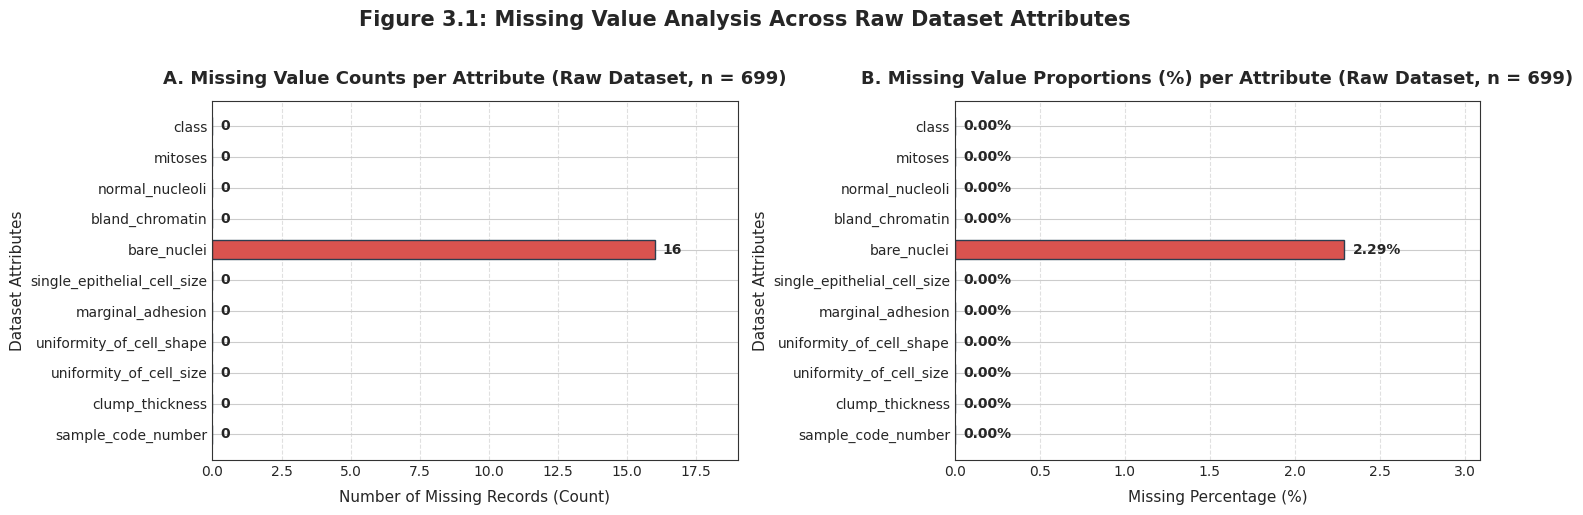

Raw Dataset Missing Values Summary (Total records = 699):
  - bare_nuclei: 16 missing records (2.29%)
  - All other 10 attributes: 0 missing records (0.00%)


In [20]:
# Calculate missing values counts and percentages from original raw dataset (n = 699)
missing_counts = df.isna().sum()
missing_pcts = (missing_counts / len(df)) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot A: Absolute missing counts
colors_counts = ["#d9534f" if c > 0 else "#2b7bba" for c in missing_counts]
bars_count = axes[0].barh(missing_counts.index, missing_counts.values, color=colors_counts, edgecolor="#2c3e50", height=0.6)
axes[0].set_title("A. Missing Value Counts per Attribute (Raw Dataset, n = 699)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Number of Missing Records (Count)", fontsize=11, labelpad=8)
axes[0].set_ylabel("Dataset Attributes", fontsize=11)
axes[0].set_xlim(0, max(missing_counts.values) + 3)
axes[0].grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars_count:
    w = bar.get_width()
    axes[0].text(w + 0.3, bar.get_y() + bar.get_height()/2, f"{int(w)}", va="center", ha="left", fontsize=10, fontweight="bold")

# Subplot B: Missing percentages
colors_pcts = ["#d9534f" if p > 0 else "#2ecc71" for p in missing_pcts]
bars_pct = axes[1].barh(missing_pcts.index, missing_pcts.values, color=colors_pcts, edgecolor="#2c3e50", height=0.6)
axes[1].set_title("B. Missing Value Proportions (%) per Attribute (Raw Dataset, n = 699)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Missing Percentage (%)", fontsize=11, labelpad=8)
axes[1].set_ylabel("Dataset Attributes", fontsize=11)
axes[1].set_xlim(0, max(missing_pcts.values) + 0.8)
axes[1].grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars_pct:
    w = bar.get_width()
    axes[1].text(w + 0.05, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va="center", ha="left", fontsize=10, fontweight="bold")

plt.suptitle("Figure 3.1: Missing Value Analysis Across Raw Dataset Attributes", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Raw Dataset Missing Values Summary (Total records = {len(df)}):")
for col in df.columns:
    if missing_counts[col] > 0:
        print(f"  - {col}: {missing_counts[col]} missing records ({missing_pcts[col]:.2f}%)")
print(f"  - All other {len(df.columns) - 1} attributes: 0 missing records (0.00%)")

### Interpretation: Missing Values Analysis

- **Scope of Visualization:** This visualization describes missingness strictly within the un-imputed **raw dataset** ($n = 699$). In the subsequent preprocessing pipeline (Task 2), missing values were resolved via training-set median imputation, leaving 0 missing values in the final modeled training ($n = 552$) and testing ($n = 139$) partitions.
- **Attribute Specificity:** Missingness is confined exclusively to a single attribute: `bare_nuclei`, which contains **16 missing entries** out of 699 records (**2.29%**). All remaining 10 attributes (including the patient identifier `sample_code_number` and target label `class`) have complete records (0% missing).
- **Documented Provenance:** The official UCI dataset documentation (`breast-cancer-wisconsin.names`, Section 8) explicitly states: *"There are 16 instances in Groups 1 to 6 that contain a single missing (i.e., unavailable) attribute value, now denoted by '?'."* The documentation records the fact of unavailability across chronological groups 1 to 6 without asserting a specific physiological or clinical mechanism for the missing measurements.
- **Methodological Evaluation:** Because missing entries represent 2.29% of total observations (substantially below the standard 5% missingness threshold where listwise deletion or imputation significantly risks distorting covariance structures), median imputation provides an effective and robust strategy. Furthermore, calculating the median replacement value strictly from the training partition ($X_{\text{train}}$) prevents data leakage into test set evaluation.


## 4. Target Class Distribution (Count Plot)

Understanding the distribution of the target variable (`class`) is crucial for evaluating class balance, selecting appropriate performance metrics, and preventing model bias toward the majority class. We examine the target distribution in both the raw and cleaned datasets.


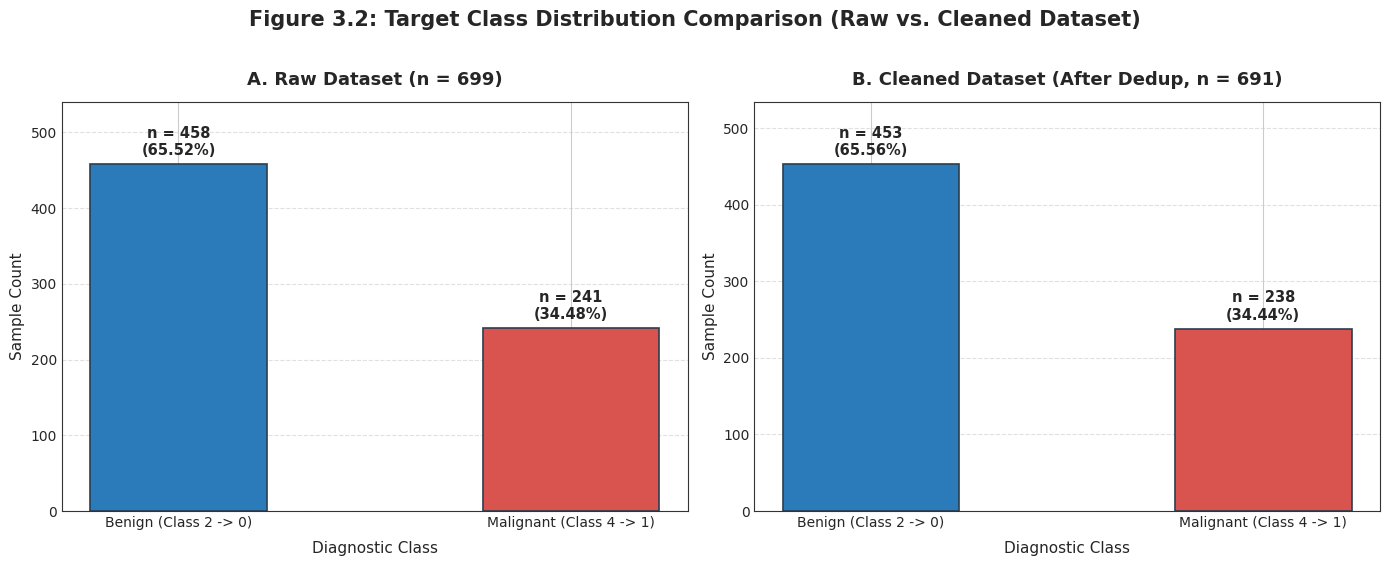

Diagnostic Class Distribution Summary:
  [Raw Dataset - Total: 699 records]
    - Benign (Class 2):    458 samples (65.52%)
    - Malignant (Class 4): 241 samples (34.48%)
    - Ratio (Benign : Malignant): 1.90 : 1
  [Cleaned Dataset - Total: 691 records (8 exact duplicates removed)]
    - Benign (Class 2 -> Encoded 0):    453 samples (65.56%)
    - Malignant (Class 4 -> Encoded 1): 238 samples (34.44%)
    - Ratio (Benign : Malignant):        1.90 : 1


In [21]:
# Calculate target class distribution for both raw and cleaned datasets dynamically
raw_counts = df["class"].value_counts().sort_index()
raw_pcts = (raw_counts / len(df)) * 100

clean_counts = df_clean["class"].value_counts().sort_index()
clean_pcts = (clean_counts / len(df_clean)) * 100

class_names = ["Benign (Class 2 -> 0)", "Malignant (Class 4 -> 1)"]
palette_bars = ["#2b7bba", "#d9534f"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Raw Dataset
bars_raw = axes[0].bar(
    class_names,
    [raw_counts[2], raw_counts[4]],
    color=palette_bars,
    edgecolor="#2c3e50",
    linewidth=1.2,
    width=0.45
)
axes[0].set_title(f"A. Raw Dataset (n = {len(df)})", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Diagnostic Class", fontsize=11, labelpad=8)
axes[0].set_ylabel("Sample Count", fontsize=11)
axes[0].set_ylim(0, max(raw_counts) * 1.18)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars_raw:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 8, f"n = {int(h)}\n({pct:.2f}%)", ha="center", va="bottom", fontsize=10.5, fontweight="bold")

# Subplot 2: Cleaned Dataset (after removing 8 exact duplicates)
bars_clean = axes[1].bar(
    class_names,
    [clean_counts[2], clean_counts[4]],
    color=palette_bars,
    edgecolor="#2c3e50",
    linewidth=1.2,
    width=0.45
)
axes[1].set_title(f"B. Cleaned Dataset (After Dedup, n = {len(df_clean)})", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Diagnostic Class", fontsize=11, labelpad=8)
axes[1].set_ylabel("Sample Count", fontsize=11)
axes[1].set_ylim(0, max(clean_counts) * 1.18)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars_clean:
    h = bar.get_height()
    pct = (h / len(df_clean)) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 8, f"n = {int(h)}\n({pct:.2f}%)", ha="center", va="bottom", fontsize=10.5, fontweight="bold")

plt.suptitle("Figure 3.2: Target Class Distribution Comparison (Raw vs. Cleaned Dataset)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Dynamic breakdown printout
print("Diagnostic Class Distribution Summary:")
print(f"  [Raw Dataset - Total: {len(df)} records]")
print(f"    - Benign (Class 2):    {raw_counts[2]} samples ({raw_pcts[2]:.2f}%)")
print(f"    - Malignant (Class 4): {raw_counts[4]} samples ({raw_pcts[4]:.2f}%)")
print(f"    - Ratio (Benign : Malignant): {raw_counts[2] / raw_counts[4]:.2f} : 1")
print(f"  [Cleaned Dataset - Total: {len(df_clean)} records (8 exact duplicates removed)]")
print(f"    - Benign (Class 2 -> Encoded 0):    {clean_counts[2]} samples ({clean_pcts[2]:.2f}%)")
print(f"    - Malignant (Class 4 -> Encoded 1): {clean_counts[4]} samples ({clean_pcts[4]:.2f}%)")
print(f"    - Ratio (Benign : Malignant):        {clean_counts[2] / clean_counts[4]:.2f} : 1")

### Interpretation: Target Class Distribution

- **Raw vs. Cleaned Record Counts:**
  - The **raw dataset** contains **699 records**: 458 benign cases (65.52%) and 241 malignant cases (34.48%), establishing a 1.90 : 1 ratio.
  - In Task 2, removing **8 exact duplicate records** (where all 11 attributes were identical) produced the **cleaned working dataset** of **691 records**: **453 benign cases (65.56%)** and **238 malignant cases (34.44%)**, maintaining an approximate **1.90 : 1** ratio ($453 / 238 \approx 1.903$).
- **Target Encoding Conventions:**
  - In the original dataset documentation, diagnostic outcomes are coded as **2 (Benign)** and **4 (Malignant)**.
  - In the supervised machine learning pipeline (Task 2), these labels were explicitly mapped to standard binary indicator values: **0 for Benign** and **1 for Malignant**. The underlying data has not been modified; this binary convention is documented throughout the workflow.
- **Methodological & Evaluation Implications for Modeling (Task 5):**
  - The dataset exhibits moderate class imbalance, with benign observations comprising roughly two-thirds of all cases.
  - In binary cancer diagnosis, classification errors carry asymmetric operational consequences: a **False Negative** (failing to identify a malignant tumor) risks delaying necessary diagnostic or therapeutic interventions, whereas a **False Positive** (flagging a benign lesion as malignant) prompts subsequent confirmatory diagnostics.
  - Because a trivial majority-class baseline predicting benign for every instance would achieve approximately **65.56% accuracy** while yielding **0% recall** on malignant cases, raw overall accuracy is an incomplete evaluation metric. Consequently, model evaluation in Task 5 must emphasize **Recall (Sensitivity)**, **Precision**, **F1-Score**, and **ROC-AUC** alongside accuracy, designating malignant cases as the positive class (`class = 1`).


## 5. Histograms to Explore Feature Distributions

Each of the nine predictive features represents a microscopic cytological characteristic graded on a discrete integer scale from **1 (baseline score)** to **10 (most severe abnormality)** as documented in the UCI dataset specification. We visualize the distributions of all nine features, stratified by diagnostic class, to assess skewness, modality, and discriminatory separation.


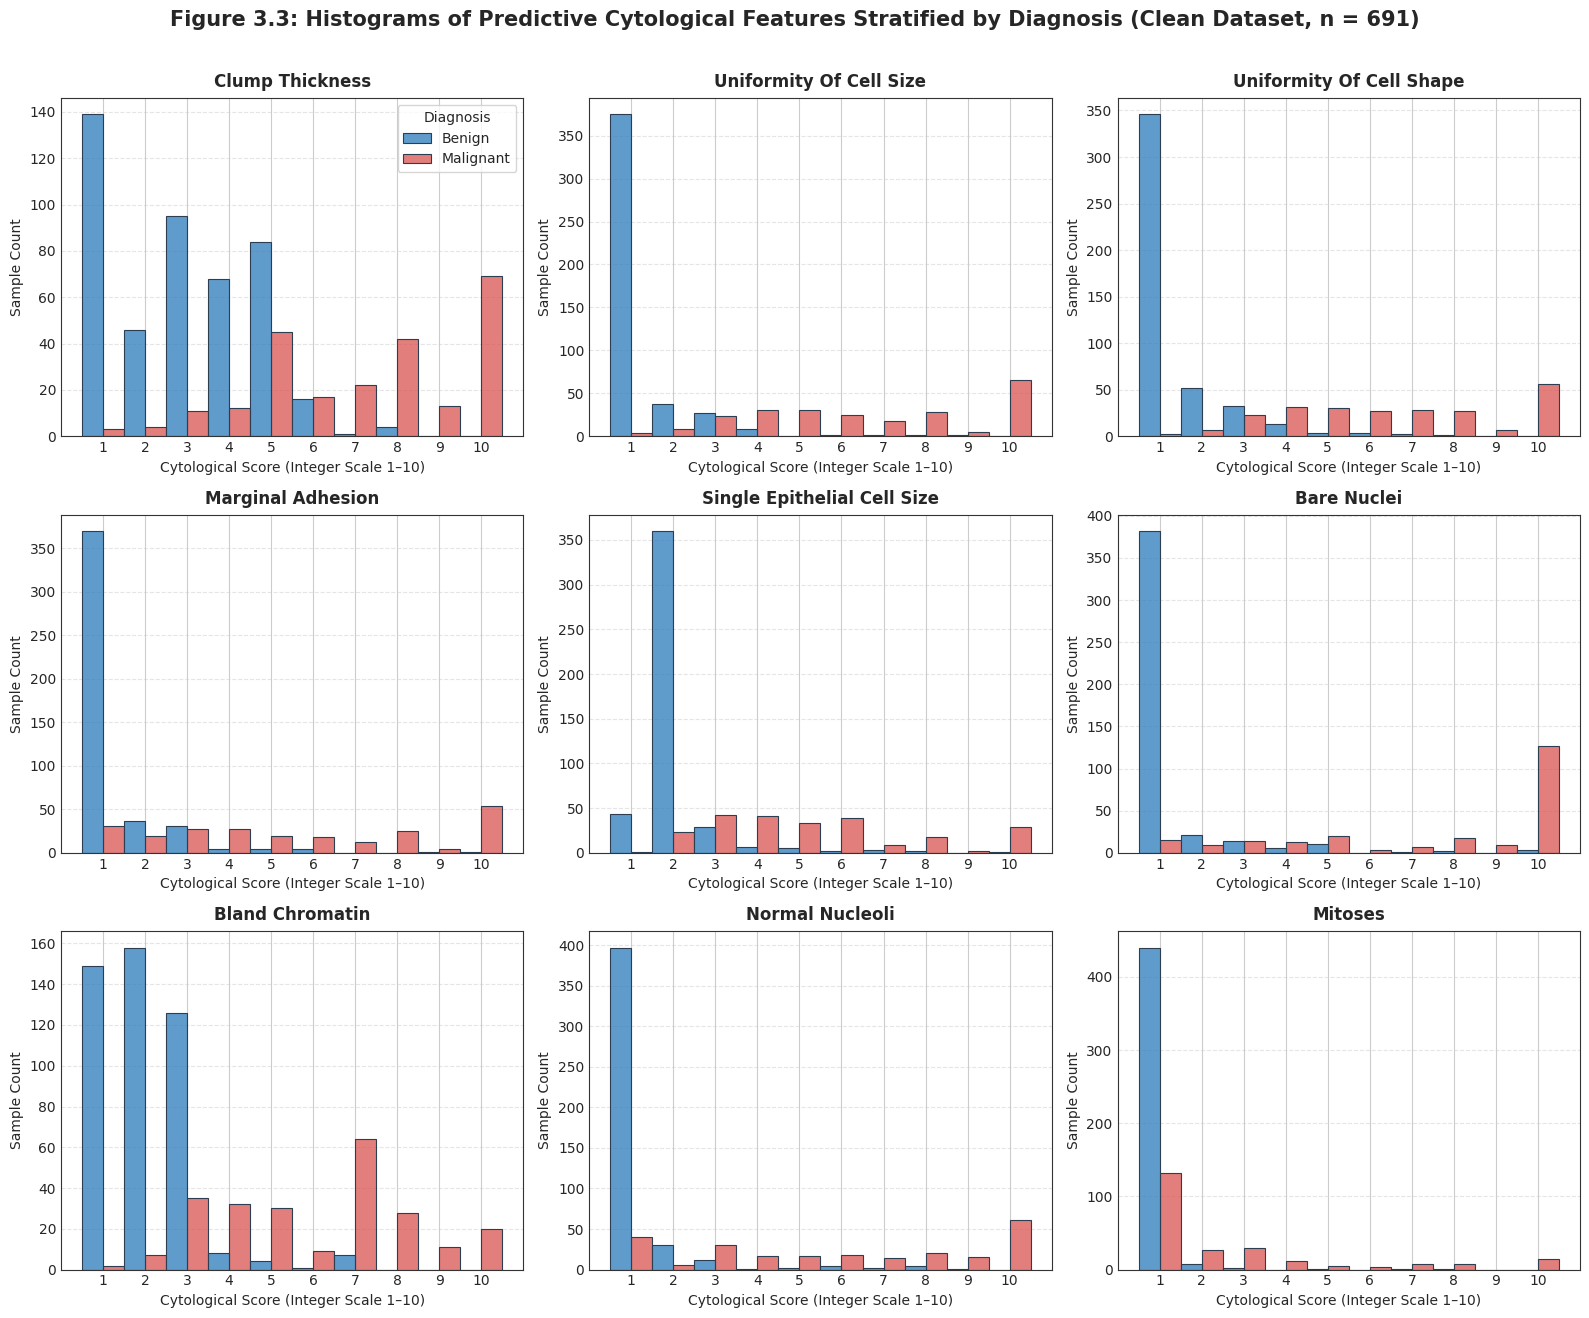

Empirical Score Distribution Summary (Calculated on Valid Non-Missing Observations):


,Feature,Benign Valid N,Benign Missing,Benign Score=1 (%),Malignant Valid N,Malignant Missing,Malignant Score=1 (%),Malignant Score=10 (%)
0,clump_thickness,453,0,139 (30.68%),238,0,3 (1.26%),69 (28.99%)
1,uniformity_of_cell_size,453,0,375 (82.78%),238,0,4 (1.68%),65 (27.31%)
2,uniformity_of_cell_shape,453,0,346 (76.38%),238,0,2 (0.84%),56 (23.53%)
3,marginal_adhesion,453,0,370 (81.68%),238,0,31 (13.03%),54 (22.69%)
4,single_epithelial_cell_size,453,0,44 (9.71%),238,0,1 (0.42%),29 (12.18%)
5,bare_nuclei,439,14,382 (87.02%),236,2,15 (6.36%),127 (53.81%)
6,bland_chromatin,453,0,149 (32.89%),238,0,2 (0.84%),20 (8.40%)
7,normal_nucleoli,453,0,397 (87.64%),238,0,40 (16.81%),61 (25.63%)
8,mitoses,453,0,440 (97.13%),238,0,132 (55.46%),14 (5.88%)


In [22]:
# Prepare data for plotting stratified histograms on discrete cytological scale (1–10)
df_vis = df_clean.copy()
df_vis["Diagnosis"] = df_vis["class"].map({2: "Benign", 4: "Malignant"})

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

# Define discrete bins centered on integers 1 through 10
bins_discrete = np.arange(0.5, 11.5, 1)

for i, col in enumerate(feature_columns):
    ax = axes[i]
    sns.histplot(
        data=df_vis,
        x=col,
        hue="Diagnosis",
        multiple="dodge",
        bins=bins_discrete,
        palette=PALETTE_CLASS,
        edgecolor="#2c3e50",
        linewidth=0.8,
        ax=ax,
        legend=(i == 0)
    )
    ax.set_title(f"{col.replace('_', ' ').title()}", fontsize=12, fontweight="bold", pad=8)
    ax.set_xlabel("Cytological Score (Integer Scale 1–10)", fontsize=10)
    ax.set_ylabel("Sample Count", fontsize=10)
    ax.set_xticks(range(1, 11))
    ax.grid(axis="y", linestyle="--", alpha=0.5)

if axes[0].get_legend():
    sns.move_legend(axes[0], "upper right", title="Diagnosis", frameon=True)

plt.suptitle("Figure 3.3: Histograms of Predictive Cytological Features Stratified by Diagnosis (Clean Dataset, n = 691)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Dynamically calculate distribution metrics based strictly on non-missing observations
score_summary_records = []
for col in feature_columns:
    b_series = df_vis[df_vis["Diagnosis"] == "Benign"][col]
    m_series = df_vis[df_vis["Diagnosis"] == "Malignant"][col]
    
    b_valid = b_series.dropna()
    m_valid = m_series.dropna()
    
    b_missing = int(b_series.isna().sum())
    m_missing = int(m_series.isna().sum())
    
    b_s1 = int((b_valid == 1).sum())
    b_pct_1 = (b_s1 / len(b_valid)) * 100
    
    m_s1 = int((m_valid == 1).sum())
    m_pct_1 = (m_s1 / len(m_valid)) * 100
    
    b_s10 = int((b_valid == 10).sum())
    b_pct_10 = (b_s10 / len(b_valid)) * 100
    
    m_s10 = int((m_valid == 10).sum())
    m_pct_10 = (m_s10 / len(m_valid)) * 100
    
    score_summary_records.append({
        "Feature": col,
        "Benign Valid N": len(b_valid),
        "Benign Missing": b_missing,
        "Benign Score=1 (%)": f"{b_s1} ({b_pct_1:.2f}%)",
        "Malignant Valid N": len(m_valid),
        "Malignant Missing": m_missing,
        "Malignant Score=1 (%)": f"{m_s1} ({m_pct_1:.2f}%)",
        "Malignant Score=10 (%)": f"{m_s10} ({m_pct_10:.2f}%)"
    })

score_summary_df = pd.DataFrame(score_summary_records)
print("Empirical Score Distribution Summary (Calculated on Valid Non-Missing Observations):")
display(score_summary_df)

### Interpretation: Feature Distribution Histograms

- **Empirical Baseline Score (Score = 1) Proportions (Non-Missing Observations):**
  - Calculating exact percentages dynamically from valid non-missing observations reveals the distinct distributional profiles of the two diagnostic cohorts:
    - **`uniformity_of_cell_size`**: **82.78%** of benign samples (375 of 453) have a score of 1, compared to **1.68%** of malignant samples (4 of 238).
    - **`uniformity_of_cell_shape`**: **76.38%** of benign samples (346 of 453) have a score of 1, compared to **0.84%** of malignant samples (2 of 238).
    - **`mitoses`**: Displays the highest concentration at score 1 for benign samples at **97.13%** (440 of 453), and is also score 1 for **55.46%** of malignant samples (132 of 238).
    - **`normal_nucleoli`**: **87.64%** of benign samples (397 of 453) have a score of 1, compared to **16.81%** of malignant samples (40 of 238).
    - **`marginal_adhesion`**: **81.68%** of benign samples (370 of 453) have a score of 1, compared to **13.03%** of malignant samples (31 of 238).
    - **`single_epithelial_cell_size`**: Only **9.71%** of benign samples (44 of 453) have a score of 1; the vast majority (**69.76%**, 316 of 453) have a score of 2.
    - **`clump_thickness`** and **`bland_chromatin`**: Show broader dispersion among benign samples, with score 1 accounting for **30.68%** (139 of 453) and **32.89%** (149 of 453), respectively.
- **Specific Distributional Characteristics of `bare_nuclei`:**
  - `bare_nuclei` contains 16 missing values across the original dataset (14 in the benign cohort, 2 in the malignant cohort).
  - Evaluated strictly across **valid non-missing observations**:
    - **Benign Cohort ($n_{\text{valid}} = 439$):** **87.02%** of samples (382 of 439) have a baseline score of 1, while only **0.68%** (3 of 439) reach a score of 10.
    - **Malignant Cohort ($n_{\text{valid}} = 236$):** Only **6.36%** of samples (15 of 236) exhibit a score of 1, whereas **53.81%** (127 of 236) concentrate at the maximum abnormality score of 10.
- **Distributional Characteristics & Skewness:**
  - All nine predictive features are graded on an ordinal integer scale from 1 to 10 as defined in the UCI study documentation.
  - In the benign cohort, distributions are heavily right-skewed, concentrating at the lower end of the scoring range (scores 1 and 2).
  - In contrast, the malignant cohort exhibits substantial spread toward elevated scores across all features, with pronounced concentration at higher values in features such as `bare_nuclei` (53.81% at score 10) and `clump_thickness` (28.99% at score 10).
- **Implications for Supervised Classification:**
  - Strong empirical separation is evident in `uniformity_of_cell_size`, `uniformity_of_cell_shape`, and `bare_nuclei`, suggesting these attributes provide substantial discriminatory signal for separating benign from malignant cases in downstream classification models.


## 6. Boxplots and Outlier Analysis

Boxplots provide a five-number summary (minimum, first quartile $Q_1$, median, third quartile $Q_3$, and maximum) while flagging potential statistical outliers beyond the standard Tukey fences:
$$\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}, \quad \text{IQR} = Q_3 - Q_1$$
We analyze distributions and outlier occurrences across both diagnostic classes.


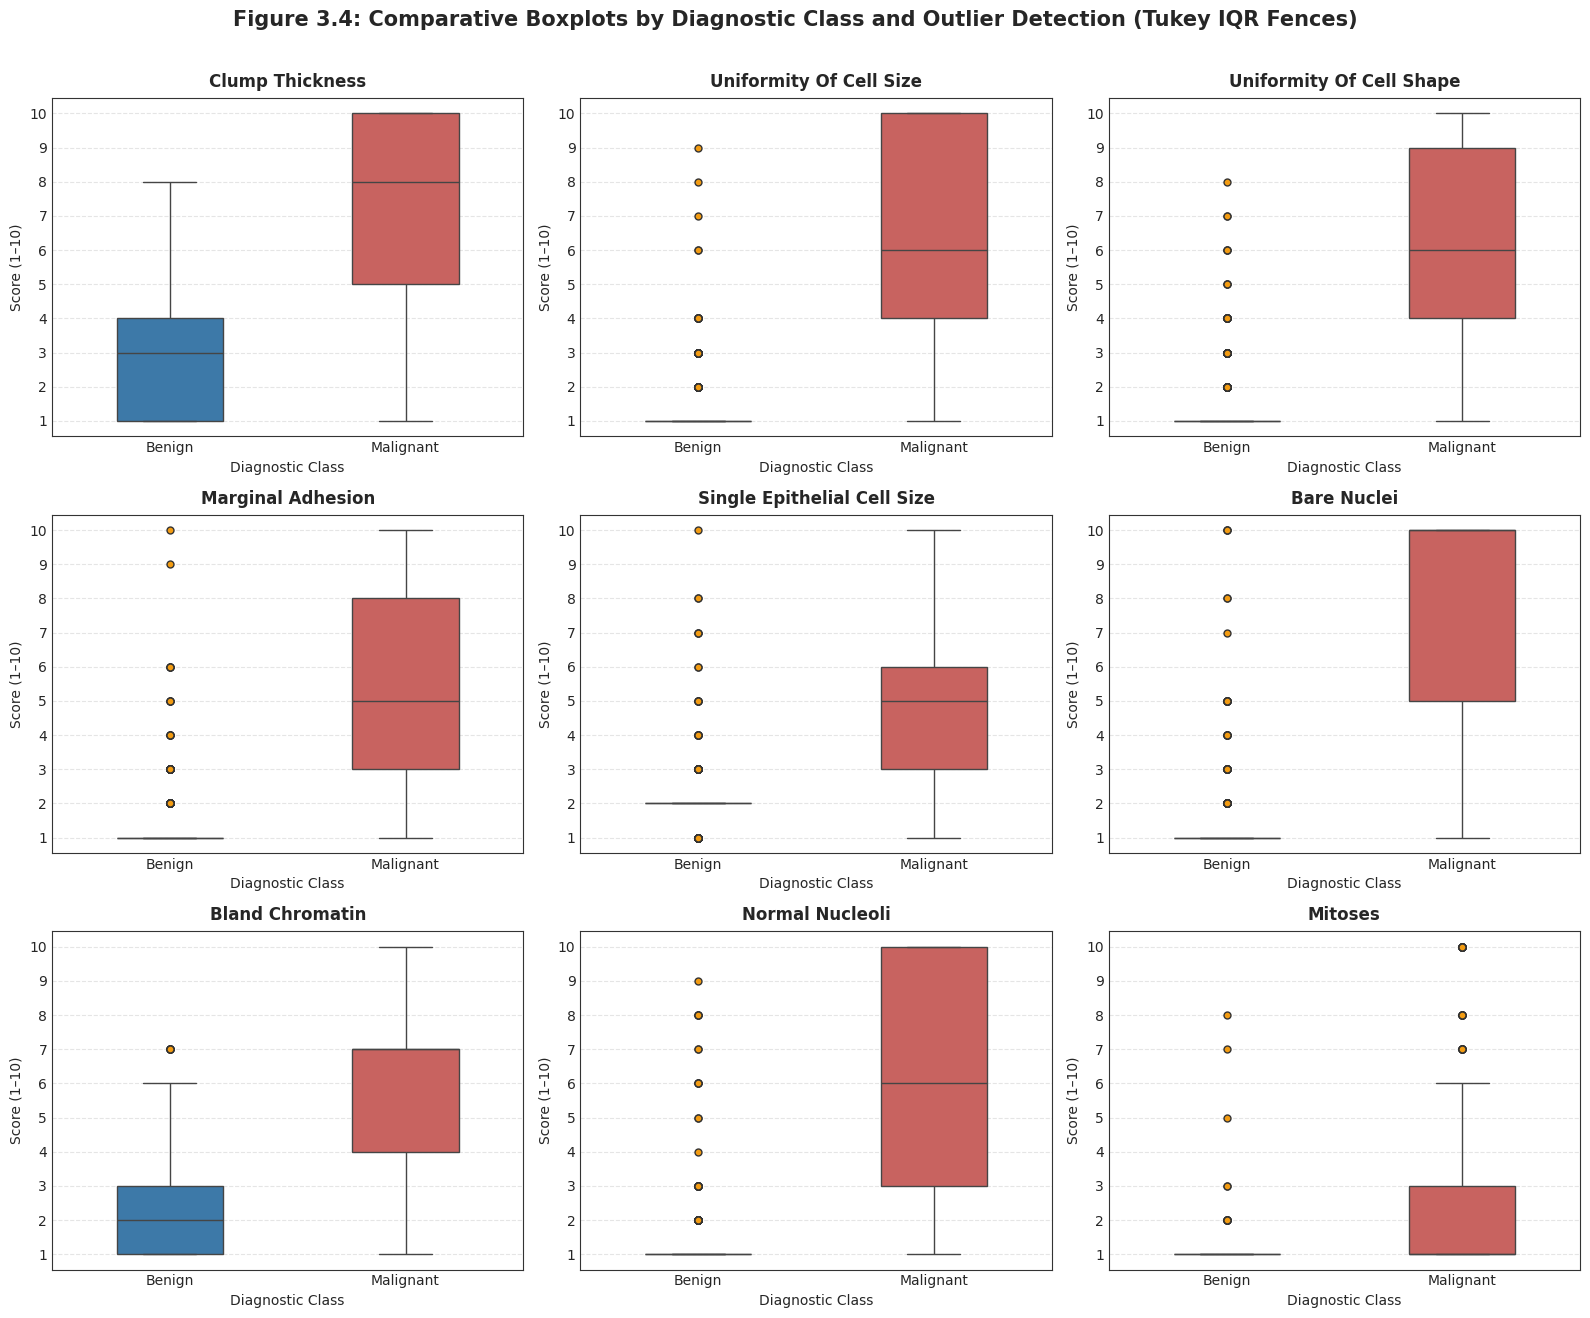

Statistical Outlier Summary Table (Tukey 1.5 * IQR Rule):


,Feature,Diagnosis,Total N,Q1,Median,Q3,IQR,Lower Fence,Upper Fence,Outlier Count,Outlier %,Outlier Values
0,uniformity_of_cell_size,Benign,453,1.0,1.0,1.0,0.0,1.0,1.0,78,17.22,"[2, 3, 4, 6, 7, 8, 9]"
1,uniformity_of_cell_shape,Benign,453,1.0,1.0,1.0,0.0,1.0,1.0,107,23.62,"[2, 3, 4, 5, 6, 7, 8]"
2,marginal_adhesion,Benign,453,1.0,1.0,1.0,0.0,1.0,1.0,83,18.32,"[2, 3, 4, 5, 6, 9, 10]"
3,single_epithelial_cell_size,Benign,453,2.0,2.0,2.0,0.0,2.0,2.0,93,20.53,"[1, 3, 4, 5, 6, 7, 8, 10]"
4,bare_nuclei,Benign,439,1.0,1.0,1.0,0.0,1.0,1.0,57,12.98,"[2.0, 3.0, 4.0, 5.0, 7.0, 8.0, 10.0]"
5,bland_chromatin,Benign,453,1.0,2.0,3.0,2.0,-2.0,6.0,7,1.55,[7]
6,normal_nucleoli,Benign,453,1.0,1.0,1.0,0.0,1.0,1.0,56,12.36,"[2, 3, 4, 5, 6, 7, 8, 9]"
7,mitoses,Benign,453,1.0,1.0,1.0,0.0,1.0,1.0,13,2.87,"[2, 3, 5, 7, 8]"
8,mitoses,Malignant,238,1.0,1.0,3.0,2.0,-2.0,6.0,29,12.18,"[7, 8, 10]"


In [23]:
# Create comparative boxplots for all predictive features
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, col in enumerate(feature_columns):
    ax = axes[i]
    sns.boxplot(
        data=df_vis,
        x="Diagnosis",
        y=col,
        hue="Diagnosis",
        legend=False,
        palette=PALETTE_CLASS,
        width=0.45,
        fliersize=5,
        flierprops={"marker": "o", "markerfacecolor": "#f39c12", "markeredgecolor": "#333333"},
        ax=ax
    )
    ax.set_title(f"{col.replace('_', ' ').title()}", fontsize=12, fontweight="bold", pad=8)
    ax.set_xlabel("Diagnostic Class", fontsize=10)
    ax.set_ylabel("Score (1–10)", fontsize=10)
    ax.set_yticks(range(1, 11))
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Figure 3.4: Comparative Boxplots by Diagnostic Class and Outlier Detection (Tukey IQR Fences)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Quantify outliers per feature and class using the standard Tukey 1.5 * IQR rule
outlier_records = []
for col in feature_columns:
    for cls_name, grp in df_vis.groupby("Diagnosis"):
        vals = grp[col].dropna()
        q1 = vals.quantile(0.25)
        med = vals.median()
        q3 = vals.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = vals[(vals < lower_bound) | (vals > upper_bound)]
        outlier_records.append({
            "Feature": col,
            "Diagnosis": cls_name,
            "Total N": len(vals),
            "Q1": q1,
            "Median": med,
            "Q3": q3,
            "IQR": iqr,
            "Lower Fence": lower_bound,
            "Upper Fence": upper_bound,
            "Outlier Count": len(outliers),
            "Outlier %": round((len(outliers) / len(vals)) * 100, 2),
            "Outlier Values": sorted(outliers.unique().tolist())
        })

outlier_summary = pd.DataFrame(outlier_records)
print("Statistical Outlier Summary Table (Tukey 1.5 * IQR Rule):")
display(outlier_summary[outlier_summary["Outlier Count"] > 0].reset_index(drop=True))

### Interpretation: Boxplots and Outlier Analysis

- **Outlier Quantification (Tukey IQR Method):**
  - Applying standard Tukey fences ($\text{Lower} = Q_1 - 1.5 \times \text{IQR}$, $\text{Upper} = Q_3 + 1.5 \times \text{IQR}$) identifies statistical outliers across the two cohorts:
    - **Benign Cohort ($n = 453$, $n = 439$ for `bare_nuclei`):**
      - `uniformity_of_cell_shape`: **107 outliers** (23.62%), values in [2, 3, 4, 5, 6, 7, 8].
      - `single_epithelial_cell_size`: **93 outliers** (20.53%), values in [1, 3, 4, 5, 6, 7, 8, 10].
      - `marginal_adhesion`: **83 outliers** (18.32%), values in [2, 3, 4, 5, 6, 9, 10].
      - `uniformity_of_cell_size`: **78 outliers** (17.22%), values in [2, 3, 4, 6, 7, 8, 9].
      - `bare_nuclei`: **57 outliers** (12.98%), values in [2.0, 3.0, 4.0, 5.0, 7.0, 8.0, 10.0].
      - `normal_nucleoli`: **56 outliers** (12.36%), values in [2, 3, 4, 5, 6, 7, 8, 9].
      - `mitoses`: **13 outliers** (2.87%), values in [2, 3, 5, 7, 8].
      - `bland_chromatin`: **7 outliers** (1.55%), value: [7].
      - `clump_thickness`: **0 outliers** (0.00%).
    - **Malignant Cohort ($n = 238$):**
      - `mitoses`: **29 outliers** (12.18%), values in [7, 8, 10].
      - All remaining eight features in the malignant cohort have **0 outliers** under Tukey's rule due to broader interquartile spreads ($\text{IQR} = 3$ to $7$).
- **Statistical Mechanism of Collapsed Interquartile Range ($IQR = 0$):**
  - An IQR outlier is a **univariate statistical classification**, not evidence of data entry error, sensor malfunction, or corrupted records.
  - In the benign cohort, several features have a concentration of values at a single score exceeding 75% of observations. Consequently, the 25th percentile ($Q_1$), the median ($Q_2$), and the 75th percentile ($Q_3$) all equal **1** (or all equal **2** for `single_epithelial_cell_size`).
  - When $Q_1 = Q_3$, the interquartile range collapses to **$\text{IQR} = 0.0$**. The resulting upper fence becomes:
    $$\text{Upper Fence} = Q_3 + 1.5 \times 0.0 = Q_3$$
    Under this strict statistical rule, any observation deviating from the central value (e.g., scores $\ge 2$ when $Q_3 = 1$, or scores $\ne 2$ when $Q_1 = Q_3 = 2$) is automatically designated as an upper outlier, regardless of whether that value represents a severe abnormality or merely minor variation.
- **Preservation Decision in Data Preprocessing:**
  - All observed values fall strictly within the valid, documented integer range of [1, 10].
  - Because these points represent valid empirical measurements within the documented attribute domains, removing or winsorizing them would artificially truncate natural variance and risk discarding informative signal.
  - Therefore, all observations flagged by Tukey's rule are **intentionally retained** without alteration for subsequent modeling.


## 7. Correlation Heatmap (Feature Relationships and Multicollinearity)

We examine linear correlations among the nine predictive features and their correlation with the binary diagnostic outcome (`class`: 0 = Benign, 1 = Malignant) to detect multicollinearity and determine feature associations with tumor malignancy. Formal two-tailed significance tests are conducted using `scipy.stats.pearsonr`.


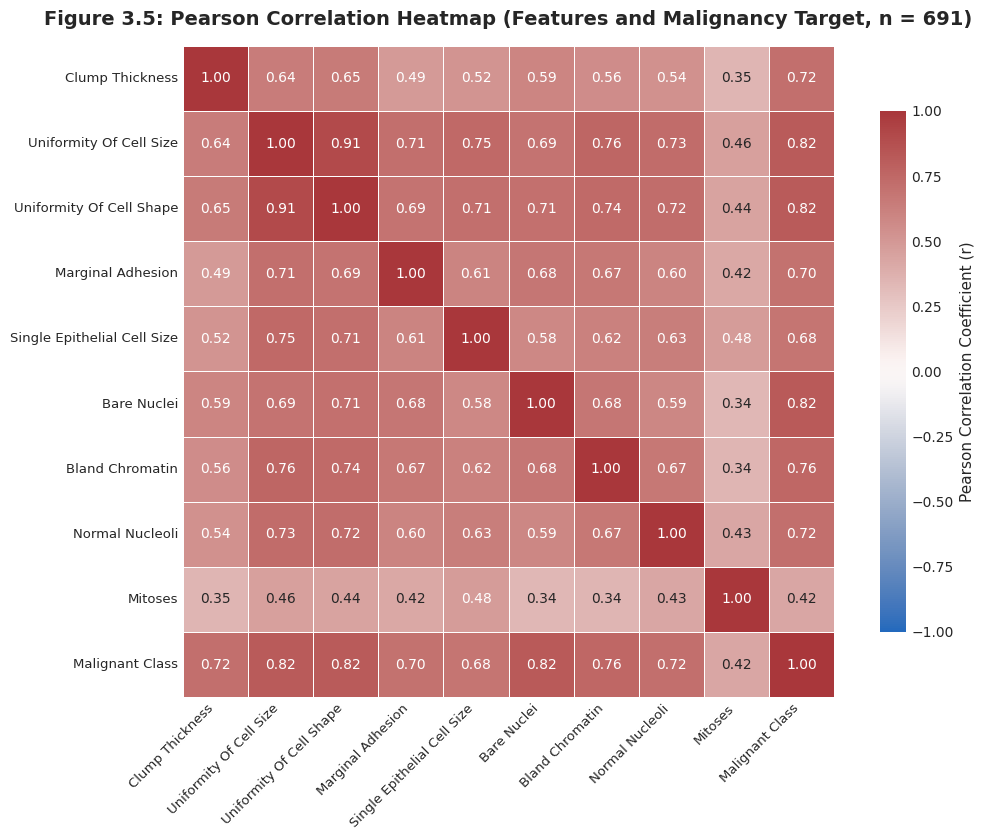

Ranked Pearson Correlation with Malignant Target (0=Benign, 1=Malignant):


,Feature,Pearson r,Rounded r,Two-tailed p-value,Significant (p < 0.001)
0,bare_nuclei,0.8205,0.82,1.25e-165,True
1,uniformity_of_cell_shape,0.8177,0.82,2.09e-167,True
2,uniformity_of_cell_size,0.8177,0.82,2.00e-167,True
3,bland_chromatin,0.7566,0.76,2.96e-129,True
4,clump_thickness,0.7169,0.72,4.70e-110,True
5,normal_nucleoli,0.7155,0.72,1.94e-109,True
6,marginal_adhesion,0.7014,0.70,2.13e-103,True
7,single_epithelial_cell_size,0.6812,0.68,2.11e-95,True
8,mitoses,0.4241,0.42,1.53e-31,True



Multicollinearity Pairwise Test (Cell Size vs. Cell Shape):
  r = 0.9054 (rounds to 0.91), two-tailed p = 1.40e-258 (Significant at p < 0.001)


In [24]:
# Build correlation matrix including the binary-encoded target (0 = Benign, 1 = Malignant)
corr_df = df_clean[feature_columns].copy()
corr_df["malignant_class"] = df_clean["class"].map({2: 0, 4: 1})

corr_matrix = corr_df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 8.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1.0,
    vmax=1.0,
    center=0,
    square=True,
    linewidths=0.7,
    cbar_kws={"label": "Pearson Correlation Coefficient (r)", "shrink": 0.8},
    ax=ax
)

ax.set_title("Figure 3.5: Pearson Correlation Heatmap (Features and Malignancy Target, n = 691)", fontsize=14, fontweight="bold", pad=15)
ax.set_xticklabels([c.replace('_', ' ').title() for c in corr_matrix.columns], fontsize=9.5, rotation=45, ha="right")
ax.set_yticklabels([c.replace('_', ' ').title() for c in corr_matrix.columns], fontsize=9.5, rotation=0)

plt.tight_layout()
plt.show()

# Conduct formal two-tailed Pearson correlation significance tests (scipy.stats.pearsonr)
target_corr_records = []
for feat in feature_columns:
    # Drop missing bare_nuclei entries to perform valid pairwise test
    valid_data = corr_df[[feat, "malignant_class"]].dropna()
    r_val, p_val = stats.pearsonr(valid_data[feat], valid_data["malignant_class"])
    target_corr_records.append({
        "Feature": feat,
        "Pearson r": round(r_val, 4),
        "Rounded r": round(r_val, 2),
        "Two-tailed p-value": f"{p_val:.2e}",
        "Significant (p < 0.001)": p_val < 0.001
    })

target_corr_df = pd.DataFrame(target_corr_records).sort_values("Pearson r", ascending=False).reset_index(drop=True)
print("Ranked Pearson Correlation with Malignant Target (0=Benign, 1=Malignant):")
display(target_corr_df)

# Pairwise test between uniformity_of_cell_size and uniformity_of_cell_shape
r_ss, p_ss = stats.pearsonr(corr_df["uniformity_of_cell_size"], corr_df["uniformity_of_cell_shape"])
print(f"\nMulticollinearity Pairwise Test (Cell Size vs. Cell Shape):")
print(f"  r = {r_ss:.4f} (rounds to {round(r_ss, 2)}), two-tailed p = {p_ss:.2e} (Significant at p < 0.001)")

### Interpretation: Correlation Heatmap and Multicollinearity

- **Correlation vs. Causation:**
  - Pearson correlation coefficients quantify the degree of linear association between pairs of features; they do not establish biological or clinical causality. A strong positive correlation between an attribute (e.g., `bare_nuclei`) and tumor malignancy indicates that elevated values frequently co-occur with malignant diagnoses in this dataset, not that cellular atypia directly causes malignant transformation.
- **Multicollinearity and Feature Redundancy:**
  - An exceptionally strong positive correlation exists between **`uniformity_of_cell_size`** and **`uniformity_of_cell_shape`** ($r = 0.9054$, rounding to **$0.91$**; two-tailed test $p = 1.40 \times 10^{-258} < 0.001$).
  - Additional notable pairwise correlations include `uniformity_of_cell_size` with `bland_chromatin` ($r = 0.76$) and with `bare_nuclei` ($r = 0.69$).
  - When two or more features exhibit high collinearity, they convey overlapping, redundant information about underlying cellular morphology.
- **Impact of Correlated Features on Machine Learning Algorithms:**
  - **Distance-Based Algorithms (e.g., KNN):** In algorithms that rely on distance metrics such as Euclidean distance ($d(\mathbf{u}, \mathbf{v}) = \sqrt{\sum (u_i - v_i)^2}$), including multiple highly correlated features effectively gives disproportionate weight to the underlying trait they jointly represent. For example, retaining both cell size and cell shape may cause morphological uniformity to dominate distance calculations relative to independent features such as `mitoses`. Feature selection or dimensionality reduction (e.g., PCA) may be considered if redundancy degrades neighborhood search.
  - **Linear Models (e.g., Logistic Regression):** Severe collinearity inflates parameter variance, making individual coefficient estimates unstable and sensitive to minor data fluctuations, although regularized formulations (L1/L2 penalty) can mitigate this effect.
  - **Kernel Methods (SVM) & Tree Ensembles (Random Forest):** Non-linear kernel SVMs and decision-tree ensembles are generally less sensitive to linear collinearity, as orthogonal decision splits evaluate features sequentially. However, feature importance rankings in random forests can be dispersed across correlated surrogates.
  - **Empirical Modeling Takeaway:** High correlation does not automatically benefit or harm classification models. The practical effect on predictive performance depends on the algorithm, the regularization applied, and the validation strategy, which will be evaluated empirically on the testing set in Tasks 4 and 5.
- **Association with Diagnostic Target (`malignant_class`) & Consistent p-values:**
  - Formal two-tailed hypothesis testing confirms that all nine predictive features exhibit positive associations with tumor malignancy that are statistically significant at **$p < 0.001$**, with p-values matching the executed statistical test table:
    - **`bare_nuclei`**: $r = 0.8205 \approx 0.82$ ($p = 1.25 \times 10^{-165}$)
    - **`uniformity_of_cell_size`**: $r = 0.8177 \approx 0.82$ ($p = 2.00 \times 10^{-167}$)
    - **`uniformity_of_cell_shape`**: $r = 0.8177 \approx 0.82$ ($p = 2.09 \times 10^{-167}$)
    - **`bland_chromatin`**: $r = 0.7566 \approx 0.76$ ($p = 2.96 \times 10^{-129}$)
    - **`clump_thickness`**: $r = 0.7169 \approx 0.72$ ($p = 4.70 \times 10^{-110}$)
    - **`normal_nucleoli`**: $r = 0.7155 \approx 0.72$ ($p = 1.94 \times 10^{-109}$)
    - **`marginal_adhesion`**: $r = 0.7014 \approx 0.70$ ($p = 2.13 \times 10^{-103}$)
    - **`single_epithelial_cell_size`**: $r = 0.6812 \approx 0.68$ ($p = 2.11 \times 10^{-95}$)
    - **`mitoses`**: $r = 0.4241 \approx 0.42$ ($p = 1.53 \times 10^{-31}$)
  - `mitoses` exhibits the lowest linear correlation ($r = 0.42$) because mitotic figures remain at score 1 across 97.13% of benign samples and 55.46% of malignant samples, with elevated scores appearing only in a subset of aggressive malignancies.


## 8. Feature Distributions Before vs. After Standardization

Feature standardization using `StandardScaler` transforms each feature to have a mean of approximately 0 ($\mu \approx 0$) and standard deviation of 1 ($\sigma = 1$):
$$z = \frac{x - \mu}{\sigma}$$

To prevent data leakage, transformation statistics were fitted exclusively on the training partition ($X_{\text{train}}$) and subsequently applied to transform both $X_{\text{train}}$ and $X_{\text{test}}$. We visualize feature distributions before and after standardization across all predictive features.


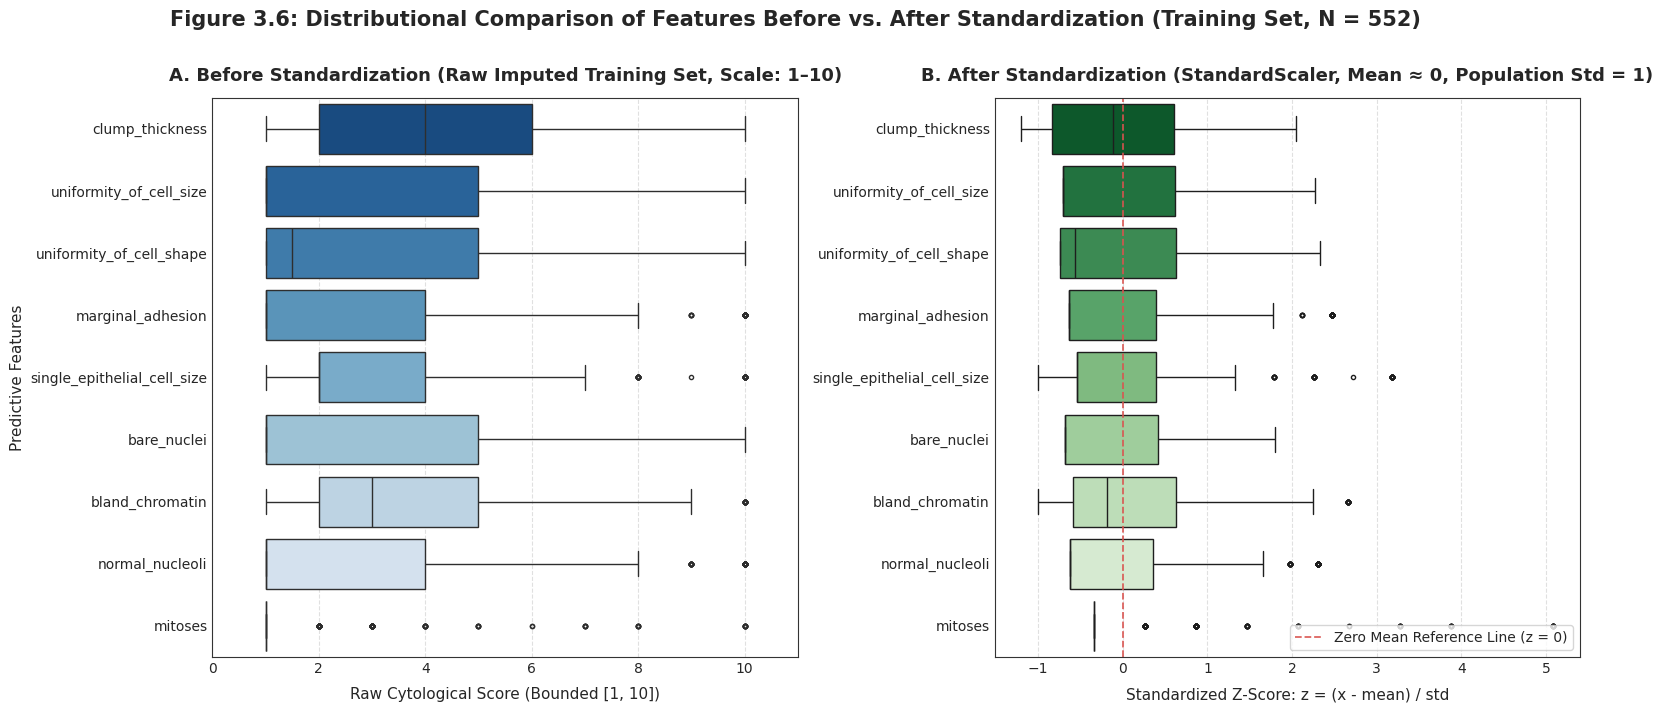

Feature Statistics Before and After Standardization (Training Partition, N = 552):


,Raw Mean,"Raw Std (ddof=0, Pop)","Raw Std (ddof=1, Sample)",Scaled Mean (≈ 0),"Scaled Std (ddof=0, Pop)","Scaled Std (ddof=1, Sample)"
clump_thickness,4.33,2.77,2.78,0.0,1.0,1.0009
uniformity_of_cell_size,3.13,3.03,3.03,-0.0,1.0,1.0009
uniformity_of_cell_shape,3.17,2.94,2.94,0.0,1.0,1.0009
marginal_adhesion,2.86,2.90,2.90,0.0,1.0,1.0009
single_epithelial_cell_size,3.16,2.15,2.15,0.0,1.0,1.0009
bare_nuclei,3.49,3.63,3.63,0.0,1.0,1.0009
bland_chromatin,3.46,2.46,2.46,0.0,1.0,1.0009
normal_nucleoli,2.91,3.08,3.08,0.0,1.0,1.0009
mitoses,1.57,1.66,1.66,-0.0,1.0,1.0009



Training Partition Empirical Range Summary:
  - Raw feature means range: 1.57 (`mitoses`) to 4.33 (`clump_thickness`)
  - Raw population std (ddof=0) range: 1.66 (`mitoses`) to 3.63 (`bare_nuclei`)
  - Raw sample std (ddof=1) range: 1.66 (`mitoses`) to 3.63 (`bare_nuclei`)
  - Scaled population standard deviations (ddof=0): all equal 1.0000
  - Scaled sample standard deviations (ddof=1): all equal 1.0009
  - Maximum absolute scaled mean deviation from 0: 1.29e-16


In [25]:
# Create side-by-side boxplots comparing distributions before and after standardization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Before standardization: Unscaled imputed training features
sns.boxplot(
    data=pd.DataFrame(X_train_imputed, columns=feature_columns),
    orient="h",
    palette="Blues_r",
    ax=axes[0],
    fliersize=3,
    linewidth=1.0
)
axes[0].set_title("A. Before Standardization (Raw Imputed Training Set, Scale: 1–10)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Raw Cytological Score (Bounded [1, 10])", fontsize=11, labelpad=8)
axes[0].set_ylabel("Predictive Features", fontsize=11)
axes[0].set_xlim(0, 11)
axes[0].grid(axis="x", linestyle="--", alpha=0.6)

# After standardization: Scaled training features (StandardScaler)
sns.boxplot(
    data=pd.DataFrame(X_train_scaled, columns=feature_columns),
    orient="h",
    palette="Greens_r",
    ax=axes[1],
    fliersize=3,
    linewidth=1.0
)
axes[1].set_title("B. After Standardization (StandardScaler, Mean ≈ 0, Population Std = 1)", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Standardized Z-Score: z = (x - mean) / std", fontsize=11, labelpad=8)
axes[1].set_ylabel("", fontsize=11)
axes[1].axvline(0, color="#d9534f", linestyle="--", linewidth=1.3, alpha=0.9, label="Zero Mean Reference Line (z = 0)")
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(axis="x", linestyle="--", alpha=0.6)

plt.suptitle("Figure 3.6: Distributional Comparison of Features Before vs. After Standardization (Training Set, N = 552)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Verification of transformation statistics comparing raw vs. scaled representations
raw_train_df = pd.DataFrame(X_train_imputed, columns=feature_columns)
scaled_train_df = pd.DataFrame(X_train_scaled, columns=feature_columns)

stats_summary = pd.DataFrame({
    "Raw Mean": raw_train_df.mean().round(2),
    "Raw Std (ddof=0, Pop)": raw_train_df.std(ddof=0).round(2),
    "Raw Std (ddof=1, Sample)": raw_train_df.std(ddof=1).round(2),
    "Scaled Mean (≈ 0)": scaled_train_df.mean().round(4),
    "Scaled Std (ddof=0, Pop)": scaled_train_df.std(ddof=0).round(4),
    "Scaled Std (ddof=1, Sample)": scaled_train_df.std(ddof=1).round(4)
})
print("Feature Statistics Before and After Standardization (Training Partition, N = 552):")
display(stats_summary)

print(f"\nTraining Partition Empirical Range Summary:")
print(f"  - Raw feature means range: {raw_train_df.mean().min():.2f} (`{raw_train_df.mean().idxmin()}`) to {raw_train_df.mean().max():.2f} (`{raw_train_df.mean().idxmax()}`)")
print(f"  - Raw population std (ddof=0) range: {raw_train_df.std(ddof=0).min():.2f} (`{raw_train_df.std(ddof=0).idxmin()}`) to {raw_train_df.std(ddof=0).max():.2f} (`{raw_train_df.std(ddof=0).idxmax()}`)")
print(f"  - Raw sample std (ddof=1) range: {raw_train_df.std(ddof=1).min():.2f} (`{raw_train_df.std(ddof=1).idxmin()}`) to {raw_train_df.std(ddof=1).max():.2f} (`{raw_train_df.std(ddof=1).idxmax()}`)")
print(f"  - Scaled population standard deviations (ddof=0): all equal {scaled_train_df.std(ddof=0).unique()[0]:.4f}")
print(f"  - Scaled sample standard deviations (ddof=1): all equal {scaled_train_df.std(ddof=1).unique()[0]:.4f}")
print(f"  - Maximum absolute scaled mean deviation from 0: {np.abs(scaled_train_df.mean()).max():.2e}")

### Interpretation: Before vs. After Standardization

- **Statistical Centering and Scaling:**
  - Prior to standardization, features operated on the raw integer scale [1, 10] with differing baseline means (ranging from **1.57** for `mitoses` to **4.33** for `clump_thickness`) and population standard deviations (ranging from **1.66** for `mitoses` to **3.63** for `bare_nuclei`). (Sample standard deviations with $\text{ddof} = 1$ likewise range from **1.66** to **3.63**).
  - Following transformation with `StandardScaler`, all nine features are centered with means approximately equal to zero ($|\mu| < 10^{-15}$, rounded to **$0.0000$**). Minor non-zero values at the 16th decimal place reflect expected floating-point rounding limits rather than incomplete centering.
  - Using population standard deviation ($\text{ddof} = 0$, matching the $\sigma = \sqrt{\frac{1}{N}\sum(x_i - \mu)^2}$ formulation used by `StandardScaler`), the standardized standard deviations equal exactly **$1.0000$** for every feature. (Reporting with sample degrees of freedom $\text{ddof} = 1$ yields $\sqrt{552/551} \approx 1.0009$).
- **Data Leakage Prevention:**
  - The `StandardScaler` was fitted strictly on the training partition ($X_{\text{train}}$, $n = 552$) and subsequently applied to transform the testing partition ($X_{\text{test}}$, $n = 139$). No parameters or summary statistics from the test set were accessed during fitting, ensuring complete freedom from data leakage.
- **Preservation of Distributional Geometry:**
  - As observed in Figure 3.6, the relative box widths, quartile spacings, skewness directions, and outlier rankings in Plot B are identical to those in Plot A.
  - Standardization is a linear affine transformation:
    $$z = \frac{x - \mu}{\sigma}$$
    It scales and translates the data without altering the underlying shape of the distribution, relative observation order, or information content.
- **Algorithmic Role in Machine Learning:**
  - **Distance-Based Models (KNN):** Standardizing features prevents attributes with larger variances (e.g., `bare_nuclei` with raw $\sigma = 3.63$) from disproportionately dominating Euclidean distance calculations over attributes with smaller dispersion (e.g., `mitoses` with raw $\sigma = 1.66$).
  - **Optimization & Kernel Methods (SVM, ANN):** Feature scaling ensures well-conditioned loss surfaces, preventing slow or oscillating gradient descent convergence and avoiding distorted kernel projections.
  - **Tree-Based Ensembles (Decision Trees, Random Forests):** Because orthogonal split finding depends only on the monotonic order of feature values, tree models are invariant to monotonic transformations and perform identically on raw and standardized inputs.


## 9. EDA Summary and Modeling Strategy

The following matrix synthesizes the empirical insights gained through Exploratory Data Analysis and defines the modeling and evaluation strategy for **Task 4 (Model Implementation)** and **Task 5 (Model Evaluation)**:

| Analytical Dimension | Empirical Observation (Task 3) | Methodological Strategy for Tasks 4 & 5 |
|:---|:---|:---|
| **Class Imbalance** | 65.56% Benign ($n=453$) vs. 34.44% Malignant ($n=238$) in cleaned data ($n=691$, 1.90 : 1 ratio). | Apply stratified splitting; set Malignant as positive class (`class = 1`); prioritize **Recall (Sensitivity)**, **F1-Score**, and **ROC-AUC** over raw accuracy. |
| **Missing Values** | 16 values in `bare_nuclei` (2.29%) in raw data ($n=699$), resolved via training median ($1.0$) imputation. | Imputation statistics fitted strictly on the training partition ($X_{\text{train}}$) to eliminate data leakage into test evaluation. |
| **Multicollinearity & Redundancy** | Strong correlation between `uniformity_of_cell_size` and `uniformity_of_cell_shape` ($r = 0.91$, $p < 0.001$). Highly correlated features share redundant information. | May amplify morphological influence in distance-based models (KNN) and inflate parameter variance in unregularized linear models; tree models and regularized classifiers are less sensitive. Model impact will be evaluated empirically. |
| **Skewness & Outliers** | Pronounced right-skewness; statistical Tukey outliers in benign cohort due to collapsed IQR ($IQR=0$). | Valid empirical observations preserved in full; robustly handled by non-parametric and tree-based classification algorithms. |
| **Feature Scaling** | Baseline training means span 1.57 (`mitoses`) to 4.33 (`clump_thickness`); raw population std spans 1.66 (`mitoses`) to 3.63 (`bare_nuclei`). Standardized to $\mu \approx 0, \sigma = 1$. | Supply standardized representations ($X_{\text{scaled}}$) to **KNN**, **SVM**, and **ANN**; tree-based models (**DT**, **RF**) evaluate on either representation. |
